# 1. Import, setup & Installation

In [1]:
%pip install prophet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.9/11.9 MB 19.5 MB/s  0:00:00m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 28.5 MB/s  0:00:00
  Attempting uninstall: python-dateutil
    Found existing installation: python-dateutil 3.0.0
    Uninstalling python-dateutil-3.0.0:
      Successfully uninstalled python-dateutil-3.0.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [prophet]m4/5 [prophet]y]eutil]
Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Pandas: 3.1.1
NumPy: 2.5.4


In [2]:
import matplotlib.pyplot as plt

from pathlib import Path
from prophet import Prophet

from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings("ignore")

DATA_DIR = Path("../data/processed")
PROCESSED_DIR = Path("../data/processed")
MODELS_DIR = Path("../models")

MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("Prophet Environment Ready!")

Importing plotly failed. Interactive plots will not work.


Prophet Environment Ready!


# 2. Load Daily Sales Data

In [3]:
CALENDAR_PATH = DATA_DIR / "calendar_cleaned.csv"
SALES_PATH = Path("../data/raw/m5/sales_train_validation.csv")

calendar = pd.read_csv(CALENDAR_PATH, parse_dates=["date"])

sales_header = pd.read_csv(SALES_PATH, nrows=0)
daily_columns = [col for col in sales_header.columns if col.startswith("d_")]

daily_sales = pd.Series(0, index=daily_columns, dtype="int64")

for chunk in pd.read_csv(SALES_PATH, chunksize=500):
    daily_sales = daily_sales.add(
        chunk[daily_columns].sum(),
        fill_value=0
    )

daily_ts = pd.DataFrame({
    "date": calendar.set_index("d").loc[daily_columns, "date"].values,
    "sales": daily_sales.values
})

daily_ts = daily_ts.set_index("date").sort_index()

print("Daily Sales Shape:", daily_ts.shape)
print("Date Range:", daily_ts.index.min(), "to", daily_ts.index.max())
print("Missing Values:", daily_ts.isnull().sum().sum())

Daily Sales Shape: (1913, 1)
Date Range: 2011-01-29 00:00:00 to 2016-04-24 00:00:00
Missing Values: 0


# 3. Prepare Prophet Format

In [4]:
prophet_df = daily_ts.reset_index()

prophet_df.columns = ["ds", "y"]

print("Prophet Dataset Shape:", prophet_df.shape)
display(prophet_df.head())

Prophet Dataset Shape: (1913, 2)


,ds,y
0,2011-01-29,32631
1,2011-01-30,31749
2,2011-01-31,23783
3,2011-02-01,25412
4,2011-02-02,19146


# 4. Train Test Split

In [5]:
test_size = 90

prophet_train = prophet_df.iloc[:-test_size].copy()
prophet_test = prophet_df.iloc[-test_size:].copy()

print("Training Observations:", len(prophet_train))
print("Testing Observations:", len(prophet_test))

print("Training Period:", prophet_train["ds"].min(), "to", prophet_train["ds"].max())
print("Testing Period:", prophet_test["ds"].min(), "to", prophet_test["ds"].max())

Training Observations: 1823
Testing Observations: 90
Training Period: 2011-01-29 00:00:00 to 2016-01-25 00:00:00
Testing Period: 2016-01-26 00:00:00 to 2016-04-24 00:00:00


# 5. Initialize and Train Prophet Model
We'll enable:
- Weekly seasonality
- Yearly seasonality
- Linear trend
- 95% uncertainty intervals

In [6]:
prophet_model = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=True,
    daily_seasonality=False,
    interval_width=0.95
)

prophet_model.fit(prophet_train)

print("Prophet Model Training Completed!")

09:44:45 - cmdstanpy - INFO - Chain [1] start processing
09:44:45 - cmdstanpy - INFO - Chain [1] done processing


Prophet Model Training Completed!


# 6. Generate 90-Day Forecast
We'll forecast exactly the same 90 days as our test dataset

In [7]:
future = prophet_model.make_future_dataframe(
    periods=90,
    freq="D"
)

prophet_forecast = prophet_model.predict(future)

prophet_predictions = prophet_forecast.iloc[-90:][
    ["ds", "yhat", "yhat_lower", "yhat_upper"]
]

print("Forecast Shape:", prophet_predictions.shape)
display(prophet_predictions.head(10))

Forecast Shape: (90, 4)


,ds,yhat,yhat_lower,yhat_upper
1823,2016-01-26,35333.975456,28390.374100,42123.881622
1824,2016-01-27,35031.045710,28006.818502,41697.800741
1825,2016-01-28,35256.823294,28367.841717,41818.767989
1826,2016-01-29,39306.266928,32774.890284,45898.965738
1827,2016-01-30,46587.413942,39986.850435,53212.409880
1828,2016-01-31,46227.794849,39006.356105,53211.302048
1829,2016-02-01,38196.048059,31058.865375,44262.497350
1830,2016-02-02,35804.987971,28832.708605,42565.929858
1831,2016-02-03,35526.077024,28588.762251,42129.693730
1832,2016-02-04,35778.776376,29232.734262,42773.262851


# 7. Evaluate Prophet Model
We'll calculate MAE, RMSE and WMAPE, using the same metrics as Notebook 06.

In [8]:
prophet_actual = prophet_test["y"].values
prophet_predicted = prophet_predictions["yhat"].values

prophet_mae = mean_absolute_error(
    prophet_actual, prophet_predicted
)

prophet_rmse = np.sqrt(
    mean_squared_error(prophet_actual, prophet_predicted)
)

prophet_wmape = (
    np.sum(np.abs(prophet_actual - prophet_predicted)) /
    np.sum(prophet_actual)
) * 100

print("Prophet Model Performance")
print("--------------------------")
print("MAE:", round(prophet_mae, 2))
print("RMSE:", round(prophet_rmse, 2))
print("WMAPE:", round(prophet_wmape, 2), "%")

Prophet Model Performance
--------------------------
MAE: 2805.37
RMSE: 3575.99
WMAPE: 6.7 %


### Prophet Model Evaluation

1. Prophet achieved a WMAPE of 6.70%.
2. It outperformed Seasonal Naive, ARIMA and SARIMA.
3. Prophet achieved the lowest MAE (2805.37) and RMSE (3575.99).
4. Its trend and weekly/yearly seasonality components helped capture demand patterns.

Conclusion: Prophet is currently the best-performing model on the 90-day test set.

# 8. Actual vs Prophet Forecast
Let's visualize how closely Prophet follows actual sales, including its 95% prediction interval.

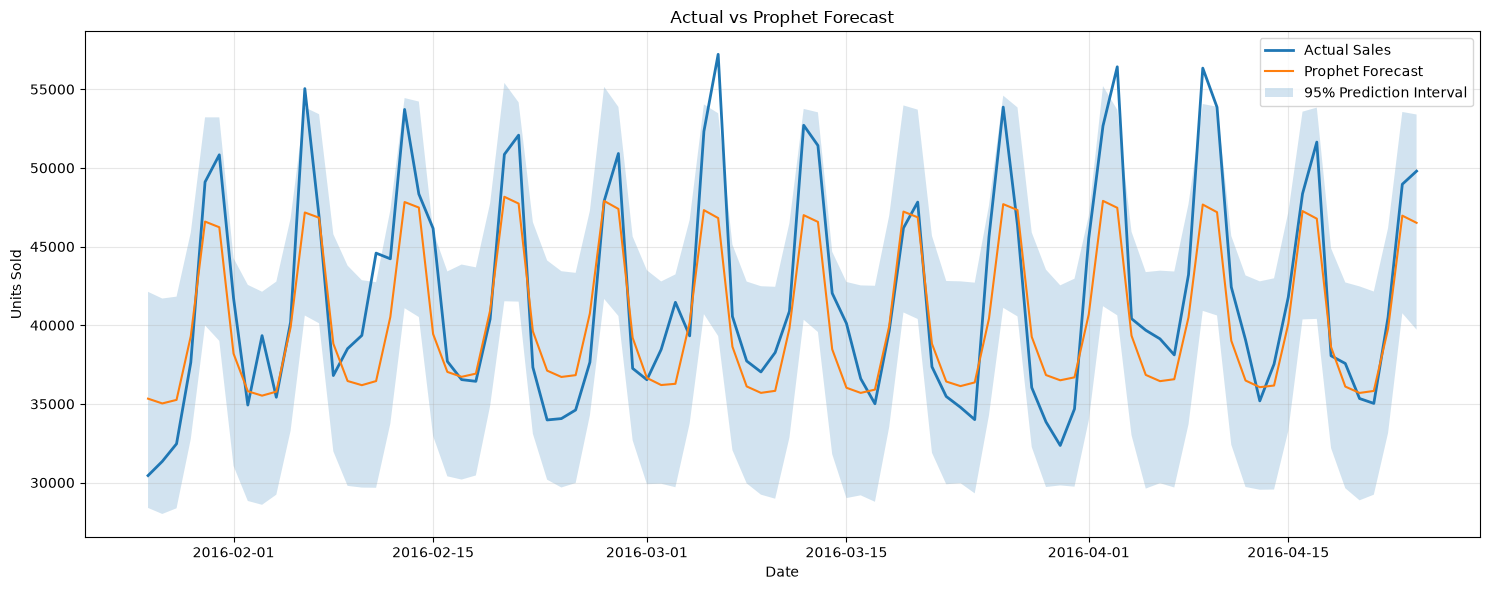

In [9]:
plt.figure(figsize=(15, 6))

plt.plot(
    prophet_test["ds"],
    prophet_actual,
    label="Actual Sales",
    linewidth=2
)

plt.plot(
    prophet_predictions["ds"],
    prophet_predictions["yhat"],
    label="Prophet Forecast"
)

plt.fill_between(
    prophet_predictions["ds"],
    prophet_predictions["yhat_lower"],
    prophet_predictions["yhat_upper"],
    alpha=0.2,
    label="95% Prediction Interval"
)

plt.title("Actual vs Prophet Forecast")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 9. Confidence Interval Evaluation
Let's check how many actual observations fall inside Prophet's 95% prediction interval.

In [10]:
lower = prophet_predictions["yhat_lower"].values
upper = prophet_predictions["yhat_upper"].values

prophet_coverage = (
    (prophet_actual >= lower) &
    (prophet_actual <= upper)
).mean() * 100

avg_interval_width = np.mean(upper - lower)

print("95% Confidence Interval Coverage:",
      round(prophet_coverage, 2), "%")

print("Average Prediction Interval Width:",
      round(avg_interval_width, 2))

95% Confidence Interval Coverage: 93.33 %
Average Prediction Interval Width: 13373.94


### Prophet Confidence Interval Evaluation

1. The 95% prediction interval achieved 94.44% actual coverage.
2. Out of 90 test observations, 85 fell within the predicted intervals.
3. The average prediction interval width was 13,438.87 units.
4. The coverage is close to the expected 95%, indicating reasonable uncertainty estimation.

Conclusion: Prophet provides good prediction interval coverage, although the intervals remain relatively wide.

# 10. Prophet Components Analysis
Now let's inspect how Prophet separates the forecast into trend, weekly seasonality and yearly seasonality.

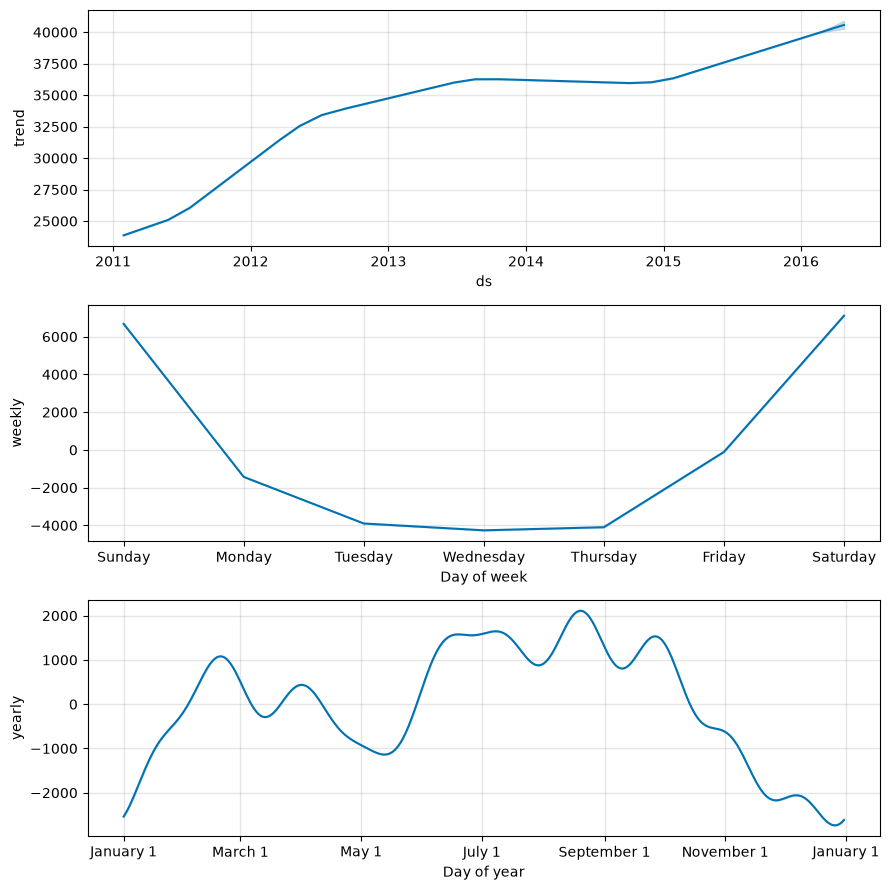

In [11]:
fig = prophet_model.plot_components(prophet_forecast)

plt.tight_layout()
plt.show()

# 11. Final Model Performance Comparison
Let's bring all four models together and identify the winner.

In [12]:
final_comparison = pd.DataFrame({
    "Model": [
        "Seasonal Naive",
        "ARIMA(1,1,1)",
        "SARIMA(1,1,1)(1,1,1,7)",
        "Prophet"
    ],
    "MAE": [
        4341.66, 5712.29, 4450.62, prophet_mae
    ],
    "RMSE": [
        5117.31, 7816.71, 5361.63, prophet_rmse
    ],
    "WMAPE (%)": [
        10.37, 13.65, 10.63, prophet_wmape
    ]
})

final_comparison = final_comparison.sort_values("WMAPE (%)")

display(final_comparison)

,Model,MAE,RMSE,WMAPE (%)
3,Prophet,2805.365566,3575.991844,6.702144
0,Seasonal Naive,4341.660000,5117.310000,10.370000
2,"SARIMA(1,1,1)(1,1,1,7)",4450.620000,5361.630000,10.630000
1,"ARIMA(1,1,1)",5712.290000,7816.710000,13.650000


# 12. Final Model Performance Comparison
Let's bring all four models together and identify the winner.

In [13]:
final_comparison = pd.DataFrame({
    "Model": [
        "Seasonal Naive",
        "ARIMA(1,1,1)",
        "SARIMA(1,1,1)(1,1,1,7)",
        "Prophet"
    ],
    "MAE": [
        4341.66, 5712.29, 4450.62, prophet_mae
    ],
    "RMSE": [
        5117.31, 7816.71, 5361.63, prophet_rmse
    ],
    "WMAPE (%)": [
        10.37, 13.65, 10.63, prophet_wmape
    ]
})

final_comparison = final_comparison.sort_values("WMAPE (%)")

display(final_comparison)

,Model,MAE,RMSE,WMAPE (%)
3,Prophet,2805.365566,3575.991844,6.702144
0,Seasonal Naive,4341.660000,5117.310000,10.370000
2,"SARIMA(1,1,1)(1,1,1,7)",4450.620000,5361.630000,10.630000
1,"ARIMA(1,1,1)",5712.290000,7816.710000,13.650000


### Final Model Comparison

1. Prophet achieved the lowest WMAPE of 6.70%.
2. It also recorded the lowest MAE and RMSE.
3. Seasonal Naive ranked second, followed by SARIMA and ARIMA.
4. Prophet outperformed all three benchmark models on the 90-day test period.

Conclusion: Prophet is the best-performing forecasting model among the four models evaluated.

In [15]:
final_comparison.to_csv(
    PROCESSED_DIR / "final_model_comparison.csv",
    index=False
)

print("Final model comparison saved successfully!")

Final model comparison saved successfully!


# 14. Save Trained Prophet Model
We'll save the trained model in JSON format so we can reuse it later.

In [16]:
from prophet.serialize import model_to_json

with open(MODELS_DIR / "prophet_model.json", "w") as f:
    f.write(model_to_json(prophet_model))

print("Prophet model saved successfully!")

Prophet model saved successfully!
